# PREDICCION DEL TRAFICO

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Tráfico medio anual

In [2]:
anual = spark.sql ("""
    SELECT t.anio, 
        ROUND(AVG(a.intensidad),1) AS trafico_medio
        FROM gold.fact_trafico a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    GROUP by t.anio
    ORDER BY t.anio
    """).toPandas()

anual

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used


,anio,trafico_medio
0,2023,441.1
1,2024,445.6
2,2025,502.2


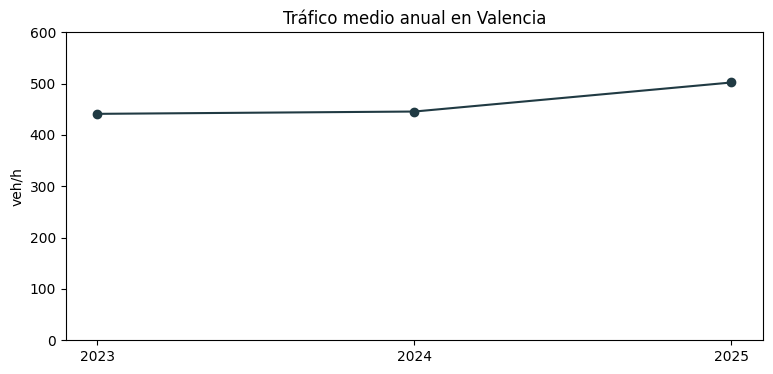

In [3]:
plt.figure(figsize=(9, 4))
plt.plot(anual["anio"], anual["trafico_medio"], marker="o", color="#203A43")
plt.title("Tráfico medio anual en Valencia")
plt.ylabel("veh/h")
plt.xticks(range(2023,2026,1))
plt.ylim(0, 600)
plt.show()

Entre 2023 y 204 la variación es cercana a un 1%, mientras que en 2025 es del 13%. Analizamos la información para detectar posibles anomalias en los datos que pueden afectar la prediccion anual

In [5]:
spark.sql("""
    SELECT t.anio,
            t.mes,
           COUNT(DISTINCT f.id_espira) AS espiras,
           COUNT(*)                    AS registros
    FROM gold.fact_trafico f
    JOIN gold.dim_tiempo t ON f.id_tiempo = t.id_tiempo
    GROUP BY t.anio, t.mes
    ORDER BY t.anio, t.mes
""").toPandas()

,anio,mes,espiras,registros
0,2023,3,948,492993
1,2023,4,953,667072
2,2023,5,958,659250
3,2023,6,955,610116
4,2023,7,956,506740
5,2023,8,947,599314
6,2023,9,947,648114
7,2023,10,948,658028
8,2023,11,946,626832
9,2023,12,941,579563


Los datos tienen huecos mensuales que no hace posible un análisis significativo anual ni de meses. Sí podemos hacer una aproximación utilizando los meses 6,7,8 y 9 que tienen informacion para los años 2023, 2024 y 2025 (si bien el 8 no está presente en 2024, haremos solo un analisis descriptivo)

In [6]:
anual_6_9 = spark.sql ("""
    SELECT t.anio,
        ROUND(AVG(a.intensidad),1) AS trafico_medio,
        COUNT(*) cantidad_registros
    FROM gold.fact_trafico a
    JOIN gold.dim_tiempo t 
        ON a.id_tiempo = t.id_tiempo
    WHERE t.mes IN (6,7,8,9)
    GROUP by t.anio
    ORDER BY t.anio
    """).toPandas()

anual_6_9

,anio,trafico_medio,cantidad_registros
0,2023,413.3,2364284
1,2024,459.4,344950
2,2025,505.6,2486230


Filtrando los meses, notamos que la variacion entre 2023 y 2025 sube de 413 a 506 veh/h (+23%).
No se hará una proyección a 2030: con 3 años, uno de ellos incompleto, una tendencia no sería fiable.
    
Tampoco se aplica SARIMA mensual, proque necesita meses seguidos y completos.

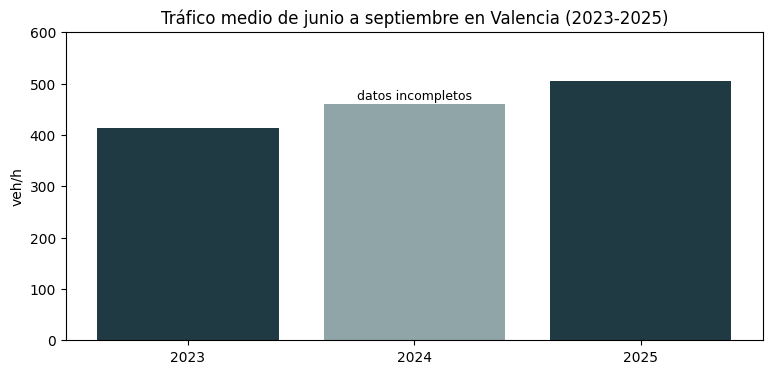

In [7]:
plt.figure(figsize=(9, 4))
plt.bar (anual_6_9["anio"], anual_6_9["trafico_medio"],color=["#203A43", "#8FA5A8", "#203A43"])
plt.title("Tráfico medio de junio a septiembre en Valencia (2023-2025)")
plt.ylabel("veh/h")
plt.xticks(range(2023,2026,1))
plt.ylim(0, 600)
plt.text(2024, anual_6_9["trafico_medio"][1] + 10, "datos incompletos", ha="center", fontsize=9)
plt.show()